In [1]:
import pandas as pd

print("My Python notebook is working!")

My Python notebook is working!


In [3]:
import os

print(os.getcwd())

C:\Users\USER


In [4]:
import os

print(os.listdir())

['.bashrc', '.bash_history', '.bash_profile', '.copilot', '.filmora_tray_version', '.ipynb_checkpoints', '.ipython', '.junie', '.jupyter', '.python_history', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'edb_pem_agent.exe', 'edb_pem_agent.exe-20261030113614', 'edb_pgagent_pg18.exe', 'edb_psqlodbc.exe', 'Favorites', 'franca-python-test', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TM.blf', 'NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'pemhttpd.exe', 'Pictures', 'postgis_3_6_pg18.exe', 'postgresql_18.exe', 'PrintHood', 'PycharmProjects', 'Recent', 'Retail_Sales_Analysis.ipynb', 'sales.csv', 'Saved Gam

In [5]:
import os

os.chdir(r"C:\Users\USER\Desktop\Fabric_Data_Engineering")

print(os.getcwd())

C:\Users\USER\Desktop\Fabric_Data_Engineering


In [6]:
import os

print(os.listdir())

['retail_sales_dataset.csv']


In [7]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [8]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


In [11]:
# Check for duplicate rows
duplicates = df.duplicated().sum()

print("Total duplicate records:", duplicates)

Total duplicate records: 0


In [12]:
# Check for duplicate Transaction IDs
duplicate_ids = df["Transaction ID"].duplicated().sum()

print("Duplicate Transaction IDs:", duplicate_ids)

Duplicate Transaction IDs: 0


In [13]:
# Check missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [14]:
# Calculate total missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [15]:
# Calculate the expected sales amount
df["Expected Amount"] = df["Quantity"] * df["Price per Unit"]

# Compare expected amount with actual amount
df["Amount Check"] = df["Total Amount"] == df["Expected Amount"]

# Count incorrect transactions
print("Incorrect sales calculations:",
      (~df["Amount Check"]).sum())

Incorrect sales calculations: 0


In [16]:
# Calculate total revenue
total_revenue = df["Total Amount"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 456000


In [17]:
total_transactions = df["Transaction ID"].nunique()

print("Total Transactions:", total_transactions)

Total Transactions: 1000


In [18]:
average_sales = df["Total Amount"].mean()

print("Average Transaction Value:", round(average_sales, 2))

Average Transaction Value: 456.0


In [19]:
category_sales = (
    df.groupby("Product Category")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [23]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [24]:
import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")

Matplotlib installed successfully!


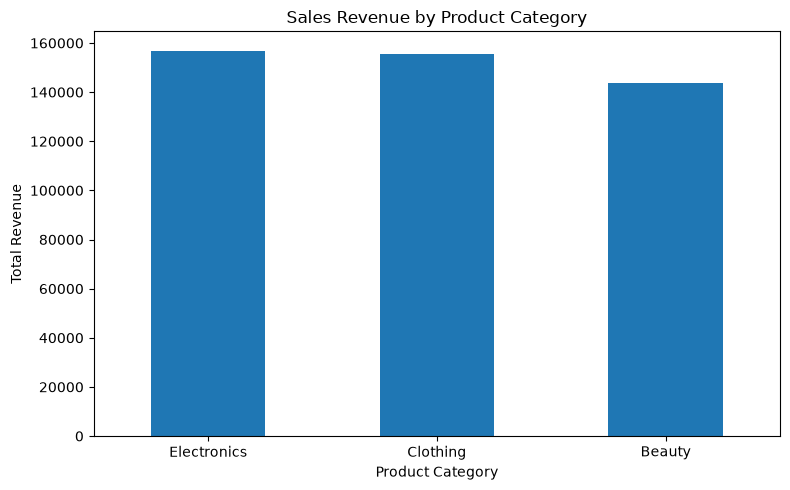

In [25]:
import matplotlib.pyplot as plt

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Sales Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month")["Total Amount"]
      .sum()
      .sort_index()
)

print(monthly_sales)

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


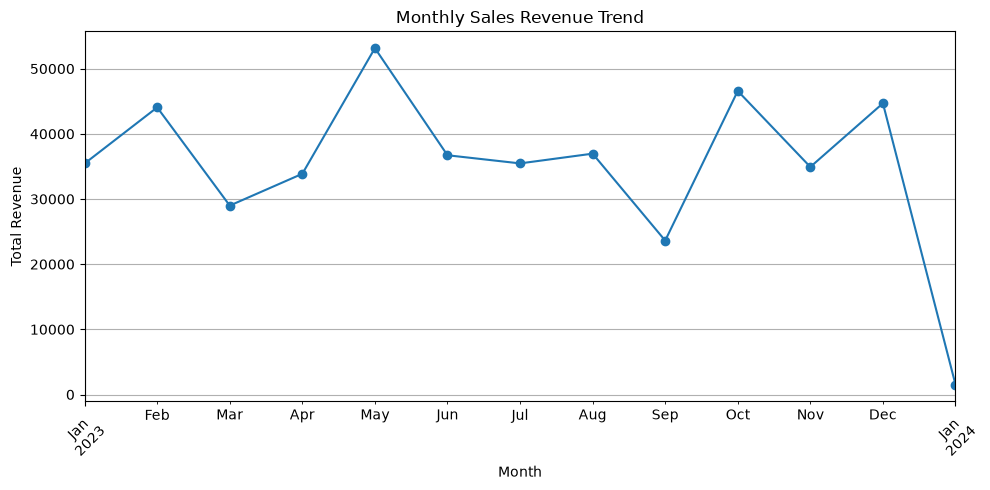

In [27]:
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
# Create a copy of the original dataset
df_silver = df.copy()

# Remove temporary analysis columns
df_silver = df_silver.drop(
    columns=["Expected Amount", "Amount Check", "Month"],
    errors="ignore"
)

# Display the cleaned dataset
df_silver.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [29]:
df_silver.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


In [30]:
print("Original dataset:", df.shape)
print("Silver dataset:", df_silver.shape)

Original dataset: (1000, 12)
Silver dataset: (1000, 9)


In [31]:
df_silver.to_csv(
    "retail_sales_silver.csv",
    index=False
)

print("Silver dataset exported successfully!")

Silver dataset exported successfully!


In [32]:
import os

print(os.listdir())

['retail_sales_dataset.csv', 'retail_sales_silver.csv']


In [33]:
gold_monthly_sales = (
    df_silver.groupby(df_silver["Date"].dt.to_period("M"))["Total Amount"]
    .sum()
    .reset_index()
)

gold_monthly_sales["Date"] = (
    gold_monthly_sales["Date"].astype(str)
)

gold_monthly_sales.rename(
    columns={"Total Amount": "Total Revenue"},
    inplace=True
)

gold_monthly_sales.head(15)

C:\Users\USER\AppData\Local\Temp\ipykernel_18768\1713491998.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gold_monthly_sales.rename(


,Date,Total Revenue
0,2023-01,35450
1,2023-02,44060
2,2023-03,28990
3,2023-04,33870
4,2023-05,53150
5,2023-06,36715
6,2023-07,35465
7,2023-08,36960
8,2023-09,23620
9,2023-10,46580


In [34]:
gold_monthly_sales.to_csv(
    "retail_sales_gold_monthly.csv",
    index=False
)

print("Gold monthly sales exported successfully!")

Gold monthly sales exported successfully!


In [35]:
import os

print(os.listdir())

['retail_sales_dataset.csv', 'retail_sales_gold_monthly.csv', 'retail_sales_silver.csv']


In [36]:
gold_category_sales = (
    df_silver.groupby("Product Category")["Total Amount"]
    .sum()
    .reset_index()
)

gold_category_sales = gold_category_sales.rename(
    columns={"Total Amount": "Total Revenue"}
)

gold_category_sales = gold_category_sales.sort_values(
    by="Total Revenue",
    ascending=False
)

gold_category_sales

,Product Category,Total Revenue
2,Electronics,156905
1,Clothing,155580
0,Beauty,143515


In [37]:
gold_category_sales.to_csv(
    "retail_sales_gold_category.csv",
    index=False
)

print("Gold category sales exported successfully!")

Gold category sales exported successfully!


In [38]:
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

retail_sales_dataset.csv
retail_sales_gold_category.csv
retail_sales_gold_monthly.csv
retail_sales_silver.csv


In [39]:
import pandas as pd

# Read the original Kaggle dataset
df_bronze = pd.read_csv("retail_sales_dataset.csv")

# Replace spaces in column names with underscores
df_bronze.columns = (
    df_bronze.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Export the Fabric-compatible Bronze dataset
df_bronze.to_csv("retail_sales_bronze.csv", index=False)

print("Bronze dataset prepared successfully!")
print(df_bronze.columns.tolist())

Bronze dataset prepared successfully!
['Transaction_ID', 'Date', 'Customer_ID', 'Gender', 'Age', 'Product_Category', 'Quantity', 'Price_per_Unit', 'Total_Amount']


In [40]:
# Make a copy of the cleaned Silver dataset
df_silver_fabric = df_silver.copy()

# Replace spaces in column names with underscores
df_silver_fabric.columns = (
    df_silver_fabric.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Export the Fabric-compatible Silver CSV
df_silver_fabric.to_csv(
    "retail_sales_silver_fabric.csv",
    index=False
)

print("Silver dataset prepared successfully!")
print(df_silver_fabric.columns.tolist())

Silver dataset prepared successfully!
['Transaction_ID', 'Date', 'Customer_ID', 'Gender', 'Age', 'Product_Category', 'Quantity', 'Price_per_Unit', 'Total_Amount']


In [41]:
# Prepare Gold monthly revenue
gold_monthly_fabric = gold_monthly_sales.copy()

# Format column names
gold_monthly_fabric.columns = (
    gold_monthly_fabric.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Export CSV
gold_monthly_fabric.to_csv(
    "retail_sales_gold_monthly_fabric.csv",
    index=False
)

print("Gold monthly dataset prepared successfully!")
print(gold_monthly_fabric.head())
print(gold_monthly_fabric.columns.tolist())

Gold monthly dataset prepared successfully!
      Date  Total_Revenue
0  2023-01          35450
1  2023-02          44060
2  2023-03          28990
3  2023-04          33870
4  2023-05          53150
['Date', 'Total_Revenue']


In [42]:
# Prepare Gold category revenue
gold_category_fabric = gold_category_sales.copy()

# Format column names for Fabric
gold_category_fabric.columns = (
    gold_category_fabric.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Export CSV
gold_category_fabric.to_csv(
    "retail_sales_gold_category_fabric.csv",
    index=False
)

print("Gold category dataset prepared successfully!")
print(gold_category_fabric)
print(gold_category_fabric.columns.tolist())

Gold category dataset prepared successfully!
  Product_Category  Total_Revenue
2      Electronics         156905
1         Clothing         155580
0           Beauty         143515
['Product_Category', 'Total_Revenue']
